# Hazards-Based vs. Risk-Based Active Learning

A simple demonstration of using a hazards-based vs. risk-based learning function to guide sampling in training emulators.

Jimmy Butler

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

rng = np.random.default_rng(5678)

## Motivation

Suppose we have access to some flood model $f$ that, given some input parameters $\theta$, outputs a flood height at a particular location $f(\theta)$. Suppose it is expensive to evaluate the flood model at these parameters, and that $\theta$ is a high dimensional vector. What do we do?

We can train an emulator of the process instead, and use active learning to guide the training of the emulator. However, training where the variance of the hazard output is high is not necessarily relevant for risks. This notebook explores and demonstrates this tension between risk and hazards based learning, motivating a use for risk based learning.

## The Hazard Model

A simple hazard model $f$ is used. Letting $\theta$ be one-dimensional, representing something that directly contributes to flood heights (like precipitation, etc.), choose $f(\theta) = \sqrt{\theta}$.

In [4]:
def hazard_func(theta):
    return np.sqrt(theta)

In [5]:
thetas = np.linspace(0,10,100)
hazards = hazard_func(thetas)

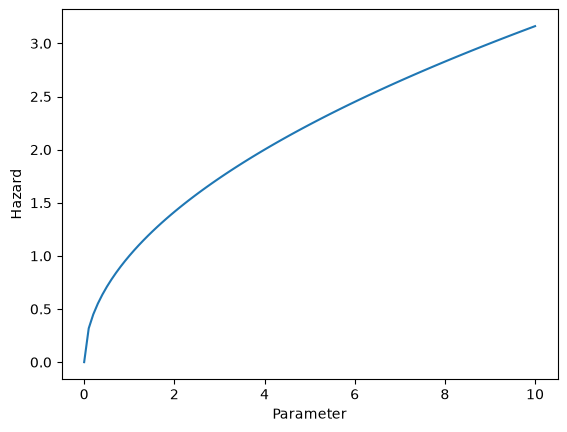

In [6]:
plt.plot(thetas, hazards)
plt.xlabel('Parameter')
plt.ylabel('Hazard');

## Emulating the Hazard Model

Let's first choose a few starting $\theta$ and $f(\theta)$ that will serve as our training data.

In [7]:
theta_train = rng.uniform(0.0, 1.0, 3)*10
theta_train = np.append(theta_train, [0,10])
hazard_train = hazard_func(theta_train)

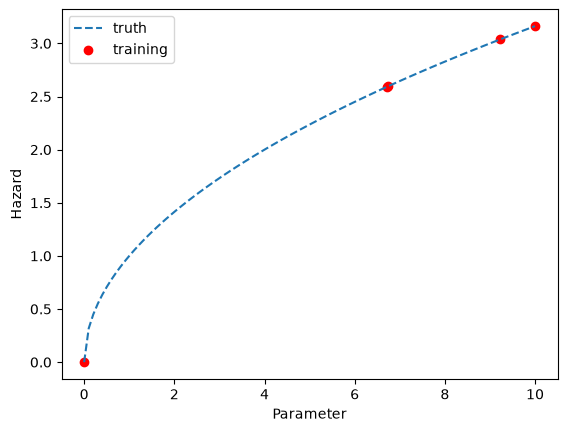

In [8]:
plt.plot(thetas, hazards, label='truth', linestyle='--')
plt.scatter(x=theta_train, y=hazard_train, c='red', label='training')
plt.xlabel('Parameter')
plt.ylabel('Hazard')
plt.legend();

Now, let's train an emulator using these training points. We'll use a gaussian process with 

In [9]:
kernel = C(1.0)*RBF(length_scale=2)
gp = GaussianProcessRegressor(kernel=kernel, alpha=0, optimizer=None)
gp.fit(theta_train.reshape(-1,1), hazard_train)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.",1**2 * RBF(length_scale=2)
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",0
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",None
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=2)
,kernel__k1__constant_value,1.0
,kernel__k1__constant_value_bounds,"(1e-05, ...)"
,kernel__k2__length_scale,2
,kernel__k2__length_scale_bounds,"(1e-05, ...)"
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",0
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False


In [10]:
new_theta = np.linspace(0, 10, 100)
preds, stds = gp.predict(new_theta.reshape(-1,1), return_std=True)
pred_variances = stds**2

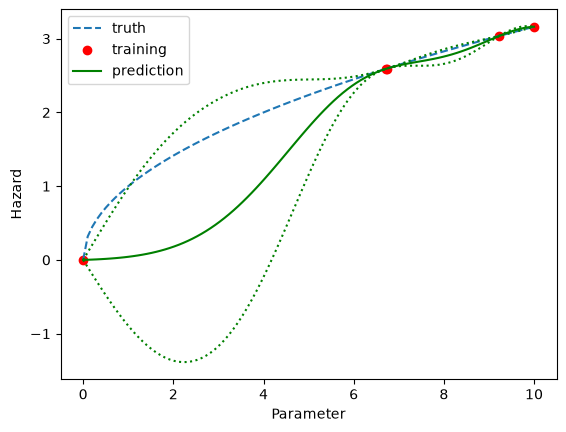

In [11]:
plt.plot(thetas, hazards, label='truth', linestyle='--')
plt.scatter(x=theta_train, y=hazard_train, c='red', label='training')
plt.plot(new_theta, preds, label='prediction', color='green')
plt.plot(new_theta, preds + 2*stds, color='green', linestyle=':')
plt.plot(new_theta, preds - 2*stds, color='green', linestyle=':')
plt.xlabel('Parameter')
plt.ylabel('Hazard')
plt.legend();

One approach to active learning is to choose the next parameter value to be the one that maximizes the posterior predictive variance. Let's plot this.

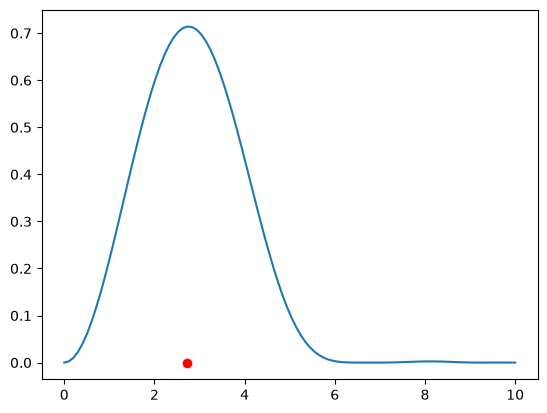

In [12]:
plt.plot(new_theta, pred_variances)
next_param = new_theta[np.argmax(pred_variances)]
plt.scatter([next_param], [0], color='red');

## Converting from Hazards to Risk

Suppose there's a levee that is at a height of $2.5$ (meters?). We might model the risk as a function of the water height via some sigmoidal function where the risk is relatively minor where the flood waters are below the levee height, but much higher and then plateau when the flood waters exceed the levee height. Letting $g(h)$ denote the risk as a function of water height $h$, we can write this in the following way:

\begin{align}
    g(h) = \frac{C}{1+\text{exp}\{-d(h-\ell)\}}
\end{align}

where $\ell$ is the levee height, $C$ specifies the maximum value at risk, and $d$ controls how fast this maximum value at risk is achieved. Let's plot this below.

In [76]:
C = 100
d = 10
l = 2.75

def risk_func(h):
    return C/(1+(np.exp(-d*(h-l))))

In [77]:
hazards_temp = np.linspace(0,4,100)
risk_temp = risk_func(hazards_temp)

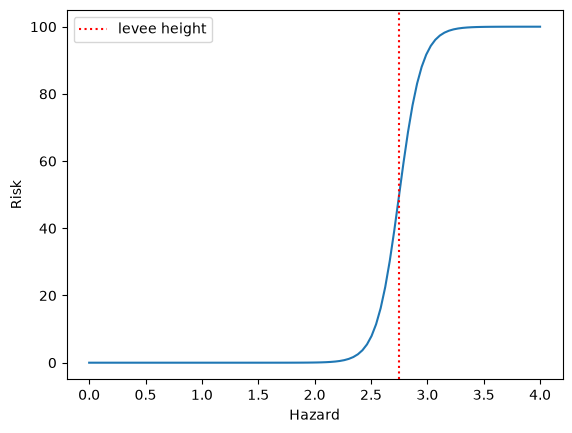

In [78]:
plt.plot(hazards_temp, risk_temp)
plt.xlabel('Hazard')
plt.ylabel('Risk')
plt.axvline(l, color='red', linestyle=':', label='levee height')
plt.legend();

This is of course a non-linear function. Passing the emulator output for a particular $\theta$, which is normally distributed via the use of a GP, will no longer necessarily yield a normal. To find the variance, we can use the delta method. If $X \sim N(\mu, \sigma^{2})$, then $\text{Var}(g(X)) \approx [g'(\mu)]^{2}\sigma^{2}$. Thus, we can take the emulator means and variances for each $\theta$, and pass them into this formula to obtain an approximation of the risk variance for each parameter.

In [79]:
# define first derivative of hazards to risk mapping
def risk_func_prime(h):
    return C*d*np.exp(-d*(h-l))/((1+np.exp(-d*(h-l)))**(2))

In [80]:
risk_variances = pred_variances*(risk_func_prime(preds))

Now, lets plot hazard and risk variance as a function of parameter value, and show the next value we would like to sample.

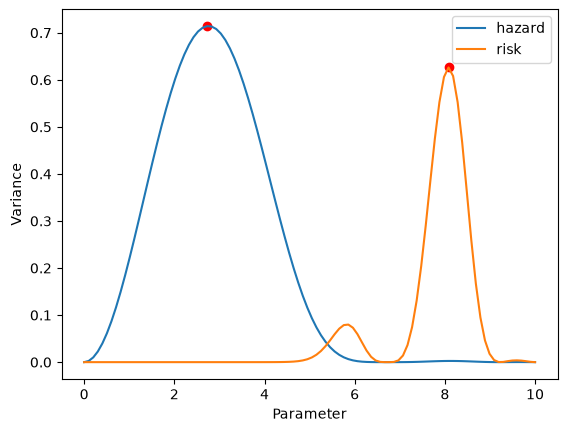

In [81]:
plt.plot(new_theta, pred_variances, label='hazard')
next_param_hazard = new_theta[np.argmax(pred_variances)]
plt.scatter([next_param_hazard], [np.max(pred_variances)], color='red')
plt.plot(new_theta, risk_variances, label='risk')
next_param_risk = new_theta[np.argmax(risk_variances)]
plt.scatter([next_param_risk], [np.max(risk_variances)], color='red')
plt.ylabel('Variance')
plt.xlabel('Parameter')
plt.legend();

For reference, we reproduce the plot of hazard emulator variability across the parameter space and the levee height.

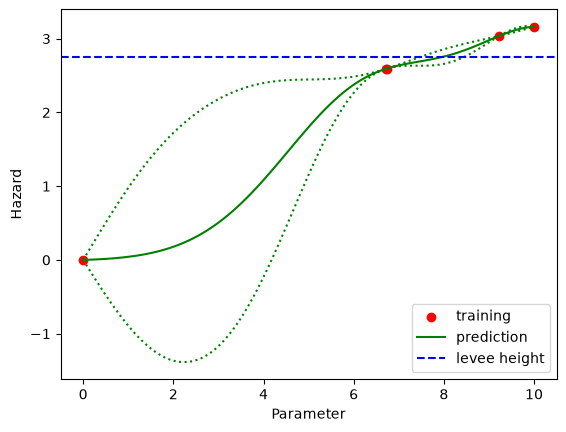

In [82]:
plt.scatter(x=theta_train, y=hazard_train, c='red', label='training')
plt.plot(new_theta, preds, label='prediction', color='green')
plt.plot(new_theta, preds + 2*stds, color='green', linestyle=':')
plt.plot(new_theta, preds - 2*stds, color='green', linestyle=':')
plt.axhline(y=l, linestyle='--', color='blue', label='levee height')
plt.xlabel('Parameter')
plt.ylabel('Hazard')
plt.legend();

## Putting it all together

Let's put all of the plots together to show the full story, from hazard emulation and variance to risk conversion to recommended next points to sample.

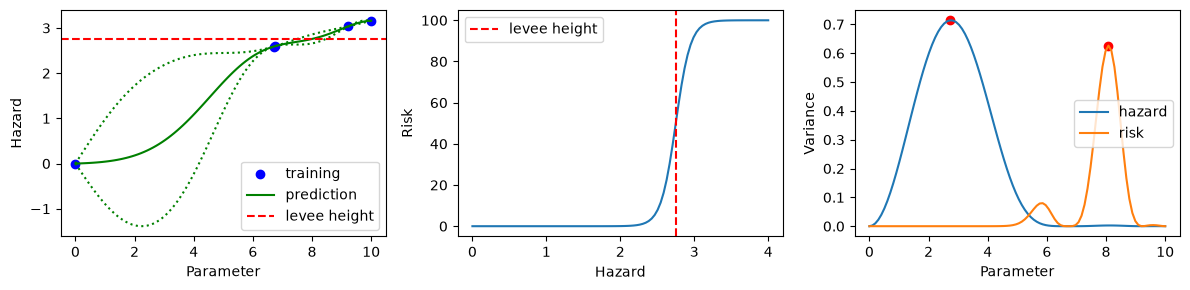

In [83]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12,3))

# hazard variance plot
ax[0].scatter(x=theta_train, y=hazard_train, c='blue', label='training')
ax[0].plot(new_theta, preds, label='prediction', color='green')
ax[0].plot(new_theta, preds + 2*stds, color='green', linestyle=':')
ax[0].plot(new_theta, preds - 2*stds, color='green', linestyle=':')
ax[0].axhline(y=l, linestyle='--', color='red', label='levee height')
ax[0].set_xlabel('Parameter')
ax[0].set_ylabel('Hazard')
ax[0].legend()

# hazards to risk conversion
ax[1].plot(hazards_temp, risk_temp)
ax[1].set_xlabel('Hazard')
ax[1].set_ylabel('Risk')
ax[1].axvline(l, color='red', linestyle='--', label='levee height')
ax[1].legend()

# z
ax[2].plot(new_theta, pred_variances, label='hazard')
next_param_hazard = new_theta[np.argmax(pred_variances)]
ax[2].scatter([next_param_hazard], [np.max(pred_variances)], color='red')
ax[2].plot(new_theta, risk_variances, label='risk')
next_param_risk = new_theta[np.argmax(risk_variances)]
ax[2].scatter([next_param_risk], [np.max(risk_variances)], color='red')
ax[2].set_ylabel('Variance')
ax[2].set_xlabel('Parameter')
ax[2].legend()

plt.tight_layout();